In [13]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

In [14]:
nCurvas = 5
nPontos = 11

YY = np.zeros((nCurvas, nPontos))
ss = np.arange(0, nCurvas, 1)
XX = np.zeros((nCurvas, nPontos +1))
XX.shape

(5, 12)

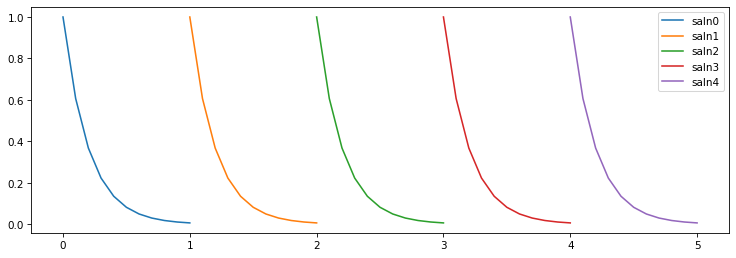

In [15]:
plt.figure(dpi=75, figsize=(12,4))
for ii in range(nCurvas):
    XX[ii,0:nPontos] = np.linspace(ii, ii+1, nPontos)
    XX[ii,nPontos] = ss[ii]
    YY[ii,:] = np.exp(-5*(XX[ii,0:nPontos]-ss[ii]))
    plt.plot(XX[ii,0:nPontos], YY[ii,:], label='saln'+str(ss[ii]))
 
plt.legend()
plt.show()


In [16]:
XX.shape, YY.shape, ss.shape

((5, 12), (5, 11), (5,))

In [17]:
XX

array([[0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. , 0. ],
       [1. , 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2. , 1. ],
       [2. , 2.1, 2.2, 2.3, 2.4, 2.5, 2.6, 2.7, 2.8, 2.9, 3. , 2. ],
       [3. , 3.1, 3.2, 3.3, 3.4, 3.5, 3.6, 3.7, 3.8, 3.9, 4. , 3. ],
       [4. , 4.1, 4.2, 4.3, 4.4, 4.5, 4.6, 4.7, 4.8, 4.9, 5. , 4. ]])

In [18]:
# Set random seed
tf.random.set_seed(42)

model = tf.keras.Sequential([
#   tf.keras.layers.Flatten(),
  tf.keras.layers.Dense(111, activation='relu'),
  tf.keras.layers.Dense(YY.shape[1], activation='linear')
])

In [19]:
# Compile the model
model.compile(loss=tf.keras.losses.mse,
              optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), 
              metrics=["mse","mae"])

In [20]:
# Fit the model
history = model.fit(XX, YY, epochs=1000, verbose=0)
print("treinada...")

treinada...


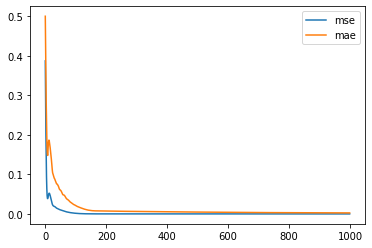

In [21]:
plt.plot(history.history["mse"], label="mse")
plt.plot(history.history["mae"], label="mae")
plt.legend()
plt.show()

In [22]:
X_pred = XX
Y_pred = model.predict(X_pred)

1/1 [==============================] - 0s 44ms/step


In [23]:
X_pred_del = np.delete(X_pred, X_pred.shape[1]-1, axis=1)
X_pred_del

array([[0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ],
       [1. , 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2. ],
       [2. , 2.1, 2.2, 2.3, 2.4, 2.5, 2.6, 2.7, 2.8, 2.9, 3. ],
       [3. , 3.1, 3.2, 3.3, 3.4, 3.5, 3.6, 3.7, 3.8, 3.9, 4. ],
       [4. , 4.1, 4.2, 4.3, 4.4, 4.5, 4.6, 4.7, 4.8, 4.9, 5. ]])

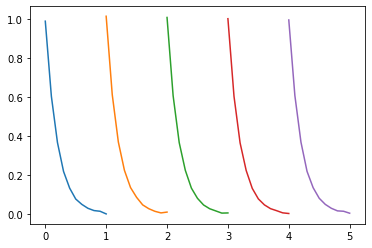

In [24]:
plt.plot(X_pred_del.T, Y_pred.T)